In [31]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PLOT_DIR = Path('muon_tag_analysis_call')
PLOT_DIR.mkdir(exist_ok=True)


In [32]:
H5_FILE = '/data/user/tvaneede/muon_tagging/data_processing/output/h5/merged.h5'

with h5py.File(H5_FILE, 'r') as f:
    reco_etot = f['RecoETot']['value'][:]   # GeV

print(f'Data events: {len(reco_etot)}')


Data events: 30


In [33]:
LIVETIME = 411785301.60  # seconds

V8_PATH = (
    '/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/datasets/flavor_globalfit/hese/combined'
    '/IC86_pass2_SnowStorm_v2_FTP_Baseline_Combined_v8-v2_fluxlessweight_PassingHESE_ExtraMuon'
    '/dataset_IC86_pass2_SnowStorm_v2_FTP_Baseline_Combined_v8-v2_fluxlessweight_PassingHESE_ExtraMuon.parquet'
)

df      = pd.read_parquet(V8_PATH)
df_muon = df[~np.isnan(df['MuonWeight'])].copy()

sim_energy         = df_muon['reco_energy'].values
sim_weights_conv   = df_muon['MuonWeightCombinedConv'].values   * LIVETIME
sim_weights_prompt = df_muon['MuonWeightCombinedPrompt'].values * LIVETIME

print(f'Simulation events: {len(sim_energy)}')
print(f'Conv weighted sum:   {sim_weights_conv.sum():.3f}')
print(f'Prompt weighted sum: {sim_weights_prompt.sum():.3f}')


Simulation events: 191
Conv weighted sum:   6.599
Prompt weighted sum: 26.854


In [34]:
E_THRESHOLD = 60e3   # GeV (60 TeV)
GEO_FACTOR  = 2.1    # geometric acceptance correction

# ── Data above threshold ──────────────────────────────────────────────────
n_above_data = np.sum(reco_etot > E_THRESHOLD)
target_above = n_above_data * GEO_FACTOR      # what each component is scaled to

# ── Simulation above threshold ────────────────────────────────────────────
above_s        = sim_energy > E_THRESHOLD
W_conv_above   = sim_weights_conv[above_s].sum()
W_prompt_above = sim_weights_prompt[above_s].sum()

# Scale each component on its own, so each one separately reproduces the
# data x GEO_FACTOR rate above 60 TeV.
scale_conv   = target_above / W_conv_above
scale_prompt = target_above / W_prompt_above

# MC statistical error on each scale factor
err_conv = scale_conv * np.sqrt(
    1.0 / n_above_data + (np.sqrt((sim_weights_conv[above_s]**2).sum()) / W_conv_above)**2)
err_prompt = scale_prompt * np.sqrt(
    1.0 / n_above_data + (np.sqrt((sim_weights_prompt[above_s]**2).sum()) / W_prompt_above)**2)

print(f'Data above 60 TeV      : {n_above_data}')
print(f'  x {GEO_FACTOR} geometrical  : {target_above:.1f}')
print()
print(f'Unscaled above 60 TeV  : conv {W_conv_above:.3f}   prompt {W_prompt_above:.3f}')
print(f'Scale factors          : conv {scale_conv:.2f} +- {err_conv:.2f}'
      f'   prompt {scale_prompt:.2f} +- {err_prompt:.2f}')
print()

sim_conv_scaled   = sim_weights_conv   * scale_conv
sim_prompt_scaled = sim_weights_prompt * scale_prompt

print('Check - scaled rate above 60 TeV:')
print(f'  conv   : {sim_conv_scaled[above_s].sum():.1f}')
print(f'  prompt : {sim_prompt_scaled[above_s].sum():.1f}')
print(f'  data   : {target_above:.1f}')


Data above 60 TeV      : 6
  x 2.1 geometrical  : 12.6

Unscaled above 60 TeV  : conv 0.652   prompt 5.997
Scale factors          : conv 19.31 +- 8.83   prompt 2.10 +- 0.91

Check - scaled rate above 60 TeV:
  conv   : 12.6
  prompt : 12.6
  data   : 12.6


In [35]:
bins      = np.logspace(np.log10(10e3), np.log10(300e3), 30)
bin_cents = 0.5 * (bins[:-1] + bins[1:])

YLIM = (5e-3, 1e3)   # low enough that the -50% band is not clipped
XLIM = (bins[0], bins[-1])   # pinned, so the shading reaches the left edge
SHADE_ALPHA = 0.8

def _hist_step(ax, vals, weights, color, label):
    w_sum = np.histogram(vals, bins=bins, weights=weights)[0]
    err   = np.sqrt(np.histogram(vals, bins=bins, weights=weights**2)[0])
    ax.stairs(w_sum, bins, color=color, linewidth=1.5, label=label)
    m = w_sum > 0
    ax.errorbar(bin_cents[m], w_sum[m], yerr=err[m], fmt='none', color=color, capsize=3)

def _hist_data(ax, vals, scale, color, label):
    n_raw = np.histogram(vals, bins=bins)[0]
    n_sc  = n_raw * scale
    err   = np.sqrt(n_raw) * scale
    ax.stairs(n_sc, bins, color=color, linewidth=1.5, label=label)
    m = n_sc > 0
    ax.errorbar(bin_cents[m], n_sc[m], yerr=err[m], fmt='none', color=color, capsize=3)

BAND_FRAC = 0.5   # +-50% on the overall normalization

def _shade_below(ax):
    """Gray the region below the 60 TeV threshold, across the full axis width."""
    ax.axvspan(XLIM[0], E_THRESHOLD, color='gray', alpha=SHADE_ALPHA,
               zorder=0, linewidth=0)

def _hist_step_noerr(ax, vals, weights, color, label):
    """Outline only, no error bars. Returns the binned contents."""
    w_sum = np.histogram(vals, bins=bins, weights=weights)[0]
    ax.stairs(w_sum, bins, color=color, linewidth=1.5, label=label)
    return w_sum

def _hist_data_noerr(ax, vals, scale, color, label):
    n_sc = np.histogram(vals, bins=bins)[0] * scale
    ax.stairs(n_sc, bins, color=color, linewidth=1.5, label=label)
    return n_sc

def _band(ax, w_sum, color, frac=BAND_FRAC, label=None):
    """Shade +-frac on the overall normalization of an already-binned component."""
    h  = np.where(w_sum > 0, w_sum, np.nan)
    lo = np.append(h * (1 - frac), h[-1] * (1 - frac))
    hi = np.append(h * (1 + frac), h[-1] * (1 + frac))
    ax.fill_between(bins, lo, hi, step='post', color=color, alpha=0.25,
                    linewidth=0, label=label)


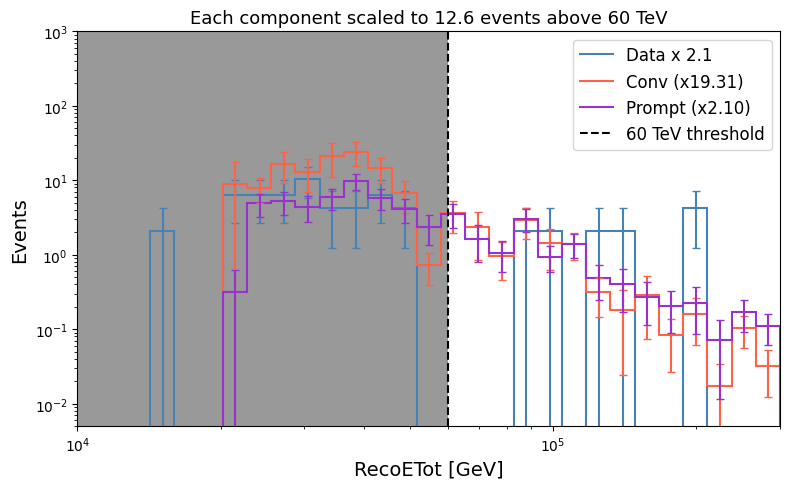

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
_shade_below(ax)

_hist_data(ax, reco_etot, GEO_FACTOR, 'steelblue', f'Data x {GEO_FACTOR}')
_hist_step(ax, sim_energy, sim_conv_scaled,   'tomato',
           f'Conv (x{scale_conv:.2f})')
_hist_step(ax, sim_energy, sim_prompt_scaled, 'darkorchid',
           f'Prompt (x{scale_prompt:.2f})')

ax.axvline(E_THRESHOLD, color='black', linestyle='--', linewidth=1.5,
           label='60 TeV threshold')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.set_xlabel('RecoETot [GeV]', fontsize=14)
ax.set_ylabel('Events', fontsize=14)
ax.set_title(f'Each component scaled to {target_above:.1f} events above 60 TeV',
             fontsize=13)
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'e_data_conv_prompt_matched_above60tev.pdf', bbox_inches='tight')
plt.show()


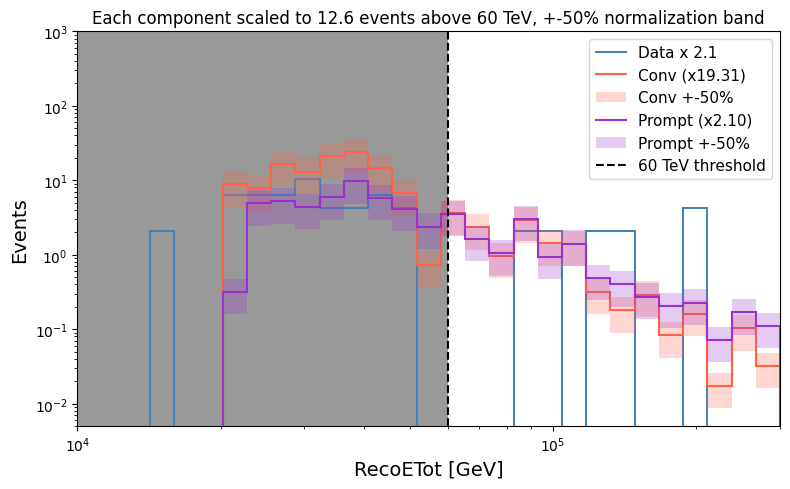

In [37]:
# Same plot without error bars. Instead, each component carries a shaded
# +-50% band on its overall normalization above 60 TeV.
fig, ax = plt.subplots(figsize=(8, 5))
_shade_below(ax)

_hist_data_noerr(ax, reco_etot, GEO_FACTOR, 'steelblue', f'Data x {GEO_FACTOR}')

h_conv = _hist_step_noerr(ax, sim_energy, sim_conv_scaled, 'tomato',
                          f'Conv (x{scale_conv:.2f})')
_band(ax, h_conv, 'tomato', label=f'Conv +-{BAND_FRAC:.0%}')

h_prompt = _hist_step_noerr(ax, sim_energy, sim_prompt_scaled, 'darkorchid',
                            f'Prompt (x{scale_prompt:.2f})')
_band(ax, h_prompt, 'darkorchid', label=f'Prompt +-{BAND_FRAC:.0%}')

ax.axvline(E_THRESHOLD, color='black', linestyle='--', linewidth=1.5,
           label='60 TeV threshold')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.set_xlabel('RecoETot [GeV]', fontsize=14)
ax.set_ylabel('Events', fontsize=14)
ax.set_title(f'Each component scaled to {target_above:.1f} events above 60 TeV, '
             f'+-{BAND_FRAC:.0%} normalization band', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'e_data_conv_prompt_matched_above60tev_band.pdf',
            bbox_inches='tight')
plt.show()
